In [1]:
import numpy as np
from sklearn.datasets import load_iris 
from sklearn.linear_model import Perceptron 

iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = (iris.target == 0)

per_clf = Perceptron(random_state=42)
per_clf.fit(X, y)

X_new = [[2, 0.5], [3, 1]]
y_pred = per_clf.predict(X_new)

In [2]:
y_pred

array([ True, False])

In [3]:
y

0       True
1       True
2       True
3       True
4       True
       ...  
145    False
146    False
147    False
148    False
149    False
Name: target, Length: 150, dtype: bool

In [4]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_valid)
rmse = root_mean_squared_error(y_valid, y_pred)




In [5]:
rmse

0.5053326657968684

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

dummy = make_pipeline(
    StandardScaler(),
    DummyRegressor(strategy="mean")
)

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_valid)

dummy_rmse = root_mean_squared_error(y_valid, dummy_pred)

print("Baseline rmse : ", dummy_rmse)
print("Neural Network rmse : ", rmse)

Baseline rmse :  1.1476260241965577
Neural Network rmse :  0.5053326657968684


In [7]:
from sklearn.ensemble import RandomForestRegressor

rfr = make_pipeline(
    StandardScaler(),
    RandomForestRegressor(random_state=42)
)

rfr.fit(X_train, y_train)

rfr_pred = rfr.predict(X_valid)

rfr_rmse = root_mean_squared_error(y_valid, rfr_pred)

print("Random Forest rmse: ", rfr_rmse)

Random Forest rmse:  0.5073847566107056


In [8]:
from sklearn.neural_network import MLPClassifier

iris = load_iris()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    iris.data, iris.target, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlpc = MLPClassifier(hidden_layer_sizes=[5])

pipeline = make_pipeline(StandardScaler(),
                         mlpc
)

pipeline.fit(X_train, y_train)

mlpc_pred = pipeline.predict(X_valid)

mlpc_rmse  = root_mean_squared_error(y_valid, mlpc_pred)
print("MLPClassifier rmse : ", mlpc_rmse)

MLPClassifier rmse :  1.1952286093343936


/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [9]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_valid, mlpc_pred)

print("MLPClassifier Accuracy:", accuracy)

MLPClassifier Accuracy: 0.32142857142857145


In [10]:
from sklearn.neural_network import MLPClassifier

iris = load_iris()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    iris.data, iris.target, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlpc = MLPClassifier(hidden_layer_sizes=[10])

pipeline = make_pipeline(StandardScaler(),
                         mlpc
)

pipeline.fit(X_train, y_train)

mlpc_pred = pipeline.predict(X_valid)

mlpc_rmse  = root_mean_squared_error(y_valid, mlpc_pred)
print("MLPClassifier rmse : ", mlpc_rmse)

MLPClassifier rmse :  0.4225771273642583


/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [11]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_valid, mlpc_pred)

print("MLPClassifier Accuracy:", accuracy)

MLPClassifier Accuracy: 0.8214285714285714


In [12]:
import tensorflow as tf 

fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist 
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]

I0000 00:00:1794288506.481189   10579 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [13]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (55000, 28, 28) (55000,)
Validation: (5000, 28, 28) (5000,)
Testing: (10000, 28, 28) (10000,)


In [14]:
X_train, X_valid, X_test = (
    X_train / 255. ,
    X_valid / 255. ,
    X_test / 255. 
)

In [15]:
print(X_train.min())
print(X_train.max())
print(X_train.dtype)

0.0
1.0
float64


In [16]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker","Bag", "Ankle boot"]

In [17]:
class_names[y_train[8]]

'Sandal'

In [18]:
class_names[y_train[4]]

'T-shirt/top'

In [19]:
tf.random.set_seed(42)

model = tf.keras.Sequential()

model.add(tf.keras.layers.Input(shape=[28, 28]))

model.add(tf.keras.layers.Flatten())

model.add(tf.keras.layers.Dense(300,activation="relu"))

model.add(tf.keras.layers.Dense(100,activation="relu"))

model.add(tf.keras.layers.Dense(10,activation="softmax"))
 

W0000 00:00:1794288512.860935   10579 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [20]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(300, activation="relu"),
    tf.keras.layers.Dense(100, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

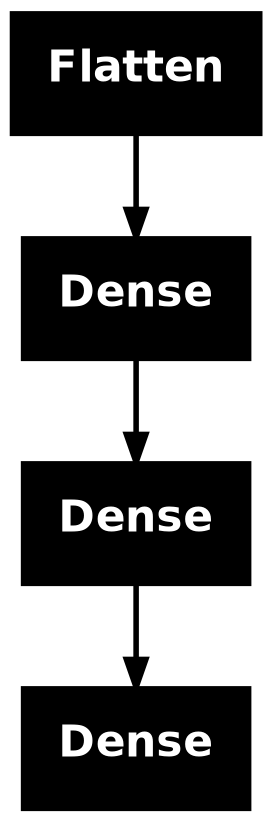

In [22]:
tf.keras.utils.plot_model(model)

In [23]:
model.layers

[<Flatten name=flatten_1, built=True>,
 <Dense name=dense_3, built=True>,
 <Dense name=dense_4, built=True>,
 <Dense name=dense_5, built=True>]

In [24]:
hidden1 = model.layers[1]

In [25]:
hidden1

<Dense name=dense_3, built=True>

In [26]:
model.get_layer('dense_3') is hidden1

True

In [27]:
weights, biases = hidden1.get_weights()

In [28]:
weights

array([[ 0.01354729, -0.01020136,  0.00858035, ...,  0.00017712,
         0.01243857, -0.05209953],
       [ 0.05224121, -0.0250017 , -0.00769862, ...,  0.02497798,
        -0.06342622,  0.0674834 ],
       [-0.0122371 ,  0.02755054,  0.05665572, ..., -0.05384026,
        -0.02647609,  0.03101606],
       ...,
       [-0.0619612 ,  0.04939572, -0.05576414, ..., -0.0348648 ,
         0.06002121, -0.00697284],
       [-0.02735706, -0.06585075,  0.0055607 , ...,  0.01785649,
        -0.07073992, -0.04939393],
       [ 0.00785822,  0.02052419,  0.068719  , ...,  0.05451111,
        -0.04306052,  0.04173664]], shape=(784, 300), dtype=float32)

In [29]:
weights.shape


(784, 300)

In [30]:
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [31]:
biases.shape

(300,)

In [32]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="sgd",
              metrics=["accuracy"])

In [33]:
history = model.fit(X_train, y_train, epochs=30,
                    validation_data=(X_valid, y_valid))

Epoch 1/30


W0000 00:00:1794288514.535047   10579 cpu_allocator_impl.cc:82] Allocation of 172480000 exceeds 10% of free system memory.


1688/1719 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7543 - loss: 0.7486

W0000 00:00:1794288517.884257   10579 cpu_allocator_impl.cc:82] Allocation of 15680000 exceeds 10% of free system memory.


1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7552 - loss: 0.7448 - val_accuracy: 0.8234 - val_loss: 0.5171
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8297 - loss: 0.4933 - val_accuracy: 0.8350 - val_loss: 0.4593
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8459 - loss: 0.4455 - val_accuracy: 0.8432 - val_loss: 0.4346
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8548 - loss: 0.4175 - val_accuracy: 0.8488 - val_loss: 0.4188
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8605 - loss: 0.3974 - val_accuracy: 0.8508 - val_loss: 0.4078
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8656 - loss: 0.3813 - val_accuracy: 0.8554 - val_loss: 0.3986
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8697 - loss: 0.3677 - val_accuracy: 0.8594 - val_loss: 0.3896
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8739 - loss: 0.3558 - val_accurac

In [34]:
history.params

{'verbose': 'auto', 'epochs': 30, 'steps': 1719}

In [35]:
history.epoch

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29]

In [36]:
history.history

{'accuracy': [0.7552363872528076,
  0.8296909332275391,
  0.8458545207977295,
  0.8548181653022766,
  0.8605272769927979,
  0.8656363487243652,
  0.8696545362472534,
  0.8738909363746643,
  0.8776000142097473,
  0.8808181881904602,
  0.8834182024002075,
  0.8862727284431458,
  0.8886181712150574,
  0.8914909362792969,
  0.8935818076133728,
  0.8961454629898071,
  0.8984727263450623,
  0.9004545211791992,
  0.9029454588890076,
  0.9046727418899536,
  0.9062181711196899,
  0.9080727100372314,
  0.9099636077880859,
  0.911472737789154,
  0.9132909178733826,
  0.9147999882698059,
  0.9159091114997864,
  0.9181636571884155,
  0.9194545745849609,
  0.9208182096481323],
 'loss': [0.7448175549507141,
  0.493315726518631,
  0.445535272359848,
  0.41753828525543213,
  0.3973974287509918,
  0.3813471496105194,
  0.3676941692829132,
  0.35577642917633057,
  0.34538596868515015,
  0.33594614267349243,
  0.32724323868751526,
  0.3190476894378662,
  0.31146499514579773,
  0.30425646901130676,
  0.297

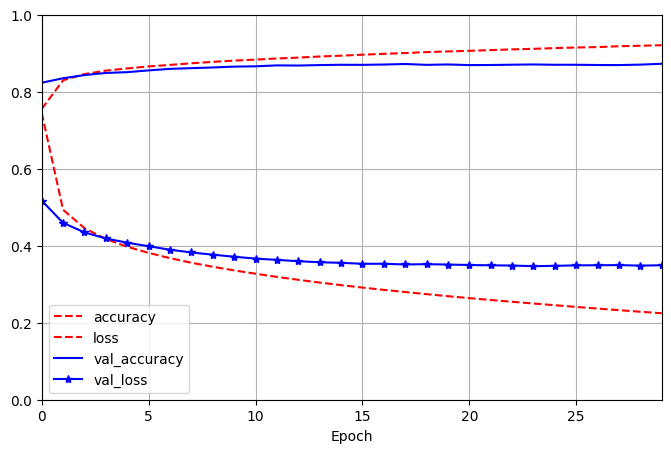

In [37]:
import matplotlib.pyplot as plt
import pandas as pd

pd.DataFrame(history.history).plot(
    figsize=(8,5), xlim=[0,29], ylim=[0, 1], xlabel="Epoch", style=["r--", "r--", "b-","b-*"])
plt.grid()
plt.show()


In [38]:
model.evaluate(X_test, y_test)

123/313 ━━━━━━━━━━━━━━━━━━━━ 0s 837us/step - accuracy: 0.8702 - loss: 0.3738

W0000 00:00:1794288625.175462   10579 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8746 - loss: 0.3642  


[0.364190936088562, 0.8745999932289124]

In [39]:
X_new = X_test[:3]
y_proba = model.predict(X_new)
y_proba.round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.09, 0.  , 0.01, 0.  , 0.9 ],
       [0.  , 0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ]],
      dtype=float32)

In [40]:
y_test[:3]

array([9, 2, 1], dtype=uint8)

In [41]:
import numpy as np
y_pred = y_proba.argmax(axis=1)
y_pred

array([9, 2, 1])

In [42]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_valid)
rmse = root_mean_squared_error(y_valid, y_pred)

In [43]:
tf.random.set_seed(42)
norm_layer = tf.keras.layers.Normalization(input_shape=X_train.shape[1:])
model = tf.keras.Sequential([
    norm_layer,
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(1)
])

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="mse", optimizer=optimizer, metrics=["root_mean_squared_error"])
norm_layer.adapt(X_train)
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))
mse_test , rmse_test = model.evaluate(X_test, y_test)

/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.8981 - root_mean_squared_error: 0.9477 - val_loss: 0.3940 - val_root_mean_squared_error: 0.6277
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4018 - root_mean_squared_error: 0.6339 - val_loss: 0.5267 - val_root_mean_squared_error: 0.7257
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3579 - root_mean_squared_error: 0.5983 - val_loss: 0.3554 - val_root_mean_squared_error: 0.5962
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3418 - root_mean_squared_error: 0.5846 - val_loss: 0.4331 - val_root_mean_squared_error: 0.6581
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3288 - root_mean_squared_error: 0.5734 - val_loss: 0.4725 - val_root_mean_squared_error: 0.6874
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3216 - root_mean_squared_error: 0.5671 - val_loss: 0.7650 - val_root_mean_squared_error: 0.8746
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

In [44]:
X_new = X_test[:3]
y_pred = model.predict(X_new)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


array([[0.43337432],
       [0.9732361 ],
       [4.9977736 ]], dtype=float32)

In [45]:
X_new.shape

(3, 8)

In [46]:
y_test[:3]

array([0.477  , 0.458  , 5.00001])

In [47]:
normalization_layer = tf.keras.layers.Normalization()
hidden_layer1 = tf.keras.layers.Dense(30, activation="relu")
hidden_layer2 = tf.keras.layers.Dense(30, activation="relu")
concat_layer  = tf.keras.layers.Concatenate()
output_layer = tf.keras.layers.Dense(1)

input_ = tf.keras.layers.Input(shape=X_train.shape[1:])
normalized = normalization_layer(input_)
hidden1 = hidden_layer1(normalized)
hidden2 = hidden_layer2(hidden1)
concat = concat_layer([normalized, hidden2])
output = output_layer(concat)

model = tf.keras.Model(inputs=[input_], outputs=[output])
model.compile(loss="mse", optimizer="adam", metrics=["root_mean_squared_error"])
normalization_layer.adapt(X_train)
model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))


Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1.4752 - root_mean_squared_error: 1.2146 - val_loss: 0.8065 - val_root_mean_squared_error: 0.8980
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 982us/step - loss: 0.4526 - root_mean_squared_error: 0.6727 - val_loss: 0.3810 - val_root_mean_squared_error: 0.6173
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3966 - root_mean_squared_error: 0.6297 - val_loss: 0.3654 - val_root_mean_squared_error: 0.6045
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3747 - root_mean_squared_error: 0.6121 - val_loss: 0.3478 - val_root_mean_squared_error: 0.5897
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 954us/step - loss: 0.3627 - root_mean_squared_error: 0.6022 - val_loss: 0.3480 - val_root_mean_squared_error: 0.5900
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3543 - root_mean_squared_error: 0.5953 - val_loss: 0.3398 - val_root_mean_squared_error: 0.5829
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 996us

In [48]:
X_new = X_test[:3]
X_new.shape

(3, 8)

In [49]:
y_pred = model.predict(X_new)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step


array([[0.49839103],
       [1.3826902 ],
       [4.7298236 ]], dtype=float32)

In [50]:
y_test[:3]

array([0.477  , 0.458  , 5.00001])